# 08 CatBoost on the G0–G3 feature sets

This notebook tunes and validates catboost on the four cumulative feature sets built in
`02_feature_engineering.ipynb`: G0 raw columns (197) → G1 + row-level features (224) → G2 + card and device
history (234) → G3 + customer history (252). All six model notebooks (04 to 09) follow the same steps and call the
same code in `src/`, so their results can be compared directly in `10_model_comparison.ipynb`.

- **Data:** `data/processed/features_v2.parquet` (build it with `02_feature_engineering.ipynb`). `src.feature_sets`
  drops the test block before anything else sees it, so this notebook never touches it.
- **Splits:** `src/split.py`. Training block = the first 472,432 rows by time; validation = the next 59,054.
- **Every fit** appends one row to `results/log.csv`. Rerunning the notebook skips anything already logged, so it
  can be stopped and restarted. Validation scores are saved to `results/preds/` (not in git) for the comparison
  notebook and a possible ensemble.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Import the model library before anything else: on macOS some model libraries clash with PyTorch's
# threading library if PyTorch is loaded first (see tests/conftest.py).
from src.models import catboost as model

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sklearn.metrics import precision_recall_curve

from src import data, experiment, feature_sets as fs, importance, segments
from src.metrics import top_rows
from src.catboost_pipeline import CatBoostPipeline

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

## 1. Settings

- `FEATURE_SETS`: the sets to validate on.
- `TUNE_ON`: `"G3"` tunes once, on the full set, and validates those settings on every set, so the sets are
  compared with the model held fixed. `None` tunes every set separately (four times the tuning cost).
- `GRID`: the settings tried during tuning, defined in the model's file in `src/models/` (logistic regression 11,
  random forest 12, MLP 16, LightGBM, XGBoost and CatBoost 20 each, so every model gets a comparable search). For a quick trial, use e.g. `model.GRID[:2]`, but log such a trial to a
  separate file (`LOG_PATH`) so it doesn't mix with the real runs.
- `SEEDS`: the validation seeds (0, 1, 2 for the group's results).
- `SAVE_OOF`: also save the time-CV fold scores of the chosen settings (4 extra fits per set, each refit as in section 4), needed to train a
  stacking model later.
- `IMPORTANCE_SET`, `IMPORTANCE_ROWS`: the feature set and the number of validation rows used for feature importance
  (section 6). More rows give steadier numbers but take longer.

In [2]:
FEATURE_SETS = ["G0", "G1", "G2", "G3"]
TUNE_ON = "G3"
GRID = model.GRID
SEEDS = [0, 1, 2]
SAVE_OOF = True
LOG_PATH = experiment.LOG_PATH          # results/log.csv
PREDS_DIR = experiment.PREDS_DIR        # results/preds/
MODELS_DIR = experiment.MODELS_DIR      # results/models/ (fitted models, reused by section 6)
IMPORTANCE_SET = FEATURE_SETS[-1]       # G3 by default: all features
IMPORTANCE_ROWS = 20_000
IMPORTANCE_DIR = ROOT / "results" / "importance"

print(f"{model.NAME}: {len(GRID)} settings to tune on {TUNE_ON or 'every set'}, seeds {SEEDS}")
print("defaults:", model.DEFAULTS)
pd.DataFrame(GRID)

catboost: 20 settings to tune on G3, seeds [0, 1, 2]
defaults: {'iterations': 3000, 'depth': 6, 'learning_rate': 0.05, 'l2_leaf_reg': 3.0, 'scale_pos_weight': 'balanced', 'thread_count': 6, 'early_stopping_rounds': 50, 'bootstrap_type': 'Bernoulli', 'subsample': 0.8, 'rsm': 0.8}


,scale_pos_weight,learning_rate,l2_leaf_reg,depth
0,balanced,0.10,3.0,8
1,1.0,0.03,10.0,6
2,1.0,0.03,3.0,6
3,1.0,0.10,3.0,8
4,1.0,0.10,10.0,6
5,balanced,0.10,1.0,6
6,1.0,0.10,10.0,4
7,1.0,0.10,1.0,4
8,balanced,0.10,10.0,4
9,balanced,0.03,3.0,8


## 2. Data

In [3]:
df, train_idx, val_idx = fs.load_features()
spec = fs.load_spec()
sets = {name: fs.feature_list(name, spec) for name in FEATURE_SETS}
print(f"rows loaded: {len(df):,} (train {len(train_idx):,}, validation {len(val_idx):,}; test block not loaded)")
print({name: len(cols) for name, cols in sets.items()})

rows loaded: 531,486 (train 472,432, validation 59,054; test block not loaded)
{'G0': 197, 'G1': 224, 'G2': 234, 'G3': 252}


## 3. Model input

**Input:** `CatBoostPipeline` (`src/catboost_pipeline.py`), the LightGBM tree input with categories turned into
strings and missing or unseen values given their own marker.

**Model:** `src/models/catboost.py`. Up to 3,000 trees with early stopping after 50 rounds without a better
average precision. Categories use CatBoost's one-hot splits only, so no target statistics are computed (no target
encoding of any column). Each tree uses a random 80% of the rows and 80% of the columns, the same for all three boosting models
(LightGBM, XGBoost, CatBoost), so their differences come from the algorithms; different seeds therefore give
slightly different models. The settings grid is a fixed random sample of 20 combinations of
depth, learning rate, L2 regularisation on the leaf weights (`l2_leaf_reg` {1, 3, 10}, the same values as LightGBM
and XGBoost) and class weight.

In [4]:
def make_pipeline(columns):
    return CatBoostPipeline(columns=columns)

## 4. Tune and validate

1. **Tune** with time CV inside the training block (seed 0): the block is cut into 30-day bins, and fold k trains on
   bins 0 to k−1 and scores bin k, so every fold scores months the model hasn't seen (4 folds). The settings with
   the highest mean average precision (PR-AUC) are chosen.
2. **Validate:** refit the chosen settings on the whole training block with each seed and score the validation
   block. The decision threshold (best F1) is picked on the validation block and stored in the log for the final
   test scoring.

**Early stopping never sees the scored rows, and the scored model trains on every training row.**
- *Tuning:* in each fold, the last 10% (by time) of the training part is held out and used only to decide when to
  stop; the model trains on the rest and the fold is scored untouched. Every setting loses the same rows, so the
  comparison between settings stays fair.
- *Validation (and the saved fold scores):* two fits. The first trains on the first 90% and finds the stopping
  point on the last 10% (number of trees); the second refits on the whole training part with that stopping point and no
  early stopping, so the most recent rows (the ones closest to the scored period) still reach the scored model.
  The validation block is used in neither fit.

So this model is compared with logistic regression and random forest on the same footing: all of them are scored
after training on the whole training block.

In [5]:
chosen = experiment.tune_and_validate(model, make_pipeline, df, train_idx, val_idx, sets, GRID,
                                      tune_on=TUNE_ON, seeds=SEEDS, log_path=LOG_PATH,
                                      preds_dir=PREDS_DIR, save_oof=SAVE_OOF)
chosen


catboost/G3: tuning 20 settings with time CV (seed 0)


.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


fold 1 {'scale_pos_weight': 'balanced', 'learning_rate': 0.1, 'l2_leaf_reg': 3.0, 'depth': 8} pr_auc=0.5238 (26s)


.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


fold 1 {'scale_pos_weight': 1.0, 'learning_rate': 0.03, 'l2_leaf_reg': 10.0, 'depth': 6} pr_auc=0.5497 (58s)


.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


... (221 outputs left out)

.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


{'G0': {'depth': 8,
  'l2_leaf_reg': 3.0,
  'learning_rate': 0.03,
  'scale_pos_weight': 1.0},
 'G1': {'depth': 8,
  'l2_leaf_reg': 3.0,
  'learning_rate': 0.03,
  'scale_pos_weight': 1.0},
 'G2': {'depth': 8,
  'l2_leaf_reg': 3.0,
  'learning_rate': 0.03,
  'scale_pos_weight': 1.0},
 'G3': {'depth': 8,
  'l2_leaf_reg': 3.0,
  'learning_rate': 0.03,
  'scale_pos_weight': 1.0}}

## 5. Results

All numbers below are read back from `results/log.csv` (and, for 5.4, the saved validation scores). Precision in
the top 1% is derived from the logged recall in the top 1% (precision = recall × fraud rows ÷ rows flagged), so it
ranks models exactly as recall does but reads more easily: recall in the top 1% is capped well below 1, because the
top 1% of rows holds fewer rows than there are fraud cases.

### 5.1 Tuning
Means over the 4 time-CV folds for the 5 best settings on each tuned set; `chosen` marks the settings validated below.

In [6]:
sizes = experiment.block_sizes(df, train_idx, val_idx)
cv, val = experiment.run_summary(model.NAME, FEATURE_SETS, LOG_PATH, sizes=sizes)
chosen_key = {name: json.dumps(p, sort_keys=True) for name, p in chosen.items()}
cv["chosen"] = [chosen_key.get(r.feature_set) == r.settings for r in cv.itertuples()]
display(cv.groupby("feature_set").head(5).round(4))

,feature_set,settings,cv_pr_auc,cv_std,cv_auroc,cv_recall_top1pct,cv_precision_top1pct,folds,chosen
0,G3,"{""depth"": 8, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.03, ""scale_pos_weight"": 1.0}",0.5605,0.0136,0.8904,0.2436,0.9382,4,True
1,G3,"{""depth"": 8, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.03, ""scale_pos_weight"": 1.0}",0.5550,0.0171,0.8897,0.2434,0.9375,4,False
2,G3,"{""depth"": 6, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.03, ""scale_pos_weight"": 1.0}",0.5533,0.0171,0.8869,0.2419,0.9314,4,False
3,G3,"{""depth"": 8, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.1, ""scale_pos_weight"": 1.0}",0.5524,0.0158,0.8855,0.2433,0.9371,4,False
4,G3,"{""depth"": 6, ""l2_leaf_reg"": 1.0, ""learning_rate"": 0.1, ""scale_pos_weight"": 1.0}",0.5492,0.0167,0.8855,0.2430,0.9355,4,False


### 5.2 Validation block, chosen settings
Mean ± sample sd over the seeds. Precision and recall "at threshold" use the F1-best threshold picked on the validation
block itself, so they are slightly optimistic; the test block is scored once with the stored threshold after the freeze.

In [7]:
val = val[[chosen_key.get(r.feature_set) == r.settings for r in val.itertuples()]]
val = val.set_index("feature_set").reindex(FEATURE_SETS)
labels = {"pr_auc": "PR-AUC", "auroc": "AUROC", "recall_top1pct": "recall top 1%",
          "precision_top1pct": "precision top 1%", "precision": "precision at threshold",
          "recall": "recall at threshold"}
table = pd.DataFrame({label: val[f"{m}_mean"].map("{:.4f}".format) + " ± " + val[f"{m}_std"].map("{:.4f}".format)
                      for m, label in labels.items()})
table["threshold"] = val["threshold_mean"].round(4)
table["seeds"] = val["seeds"]
n_val, fraud_val = sizes["val"]
print(f"Validation block: {fraud_val:,} fraud in {n_val:,} rows. The top 1% is {top_rows(n_val):,} rows, "
      f"so recall in the top 1% is at most {top_rows(n_val) / fraud_val:.3f}.")
display(table)

Validation block: 1,851 fraud in 59,054 rows. The top 1% is 591 rows, so recall in the top 1% is at most 0.319.


,PR-AUC,AUROC,recall top 1%,precision top 1%,precision at threshold,recall at threshold,threshold,seeds
feature_set,,,,,,,,
G0,0.5498 ± 0.0045,0.9040 ± 0.0009,0.2871 ± 0.0030,0.8990 ± 0.0093,0.6907 ± 0.0286,0.4362 ± 0.0085,0.2841,3
G1,0.5625 ± 0.0024,0.9077 ± 0.0008,0.2905 ± 0.0011,0.9098 ± 0.0035,0.6593 ± 0.0236,0.4677 ± 0.0095,0.2981,3
G2,0.5504 ± 0.0023,0.9068 ± 0.0007,0.2847 ± 0.0009,0.8917 ± 0.0029,0.6341 ± 0.0335,0.4747 ± 0.0159,0.2812,3
G3,0.5485 ± 0.0026,0.9059 ± 0.0023,0.2860 ± 0.0019,0.8957 ± 0.0059,0.5916 ± 0.0314,0.4925 ± 0.0168,0.2397,3


**Precision–recall curves** on the validation block (seed 0), one per feature set. PR-AUC is the area under each
curve; the dashed line is a model with no skill (precision = fraud rate).

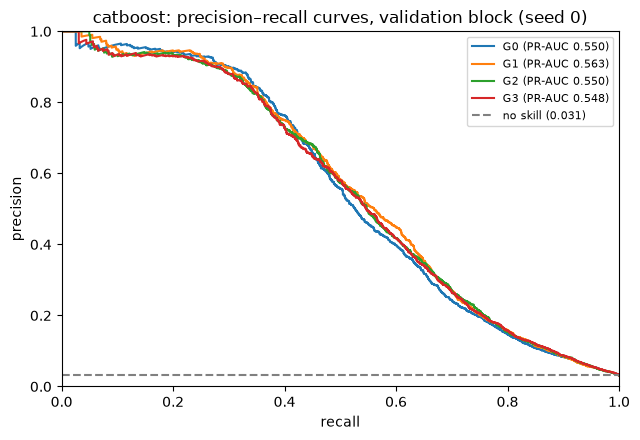

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in FEATURE_SETS:
    path = PREDS_DIR / f"{model.NAME}_{name}_val_seed0.parquet"
    if path.exists():
        p = pd.read_parquet(path)
        precision, recall, _ = precision_recall_curve(p["isFraud"], p["score"])
        ax.plot(recall, precision, label=f"{name} (PR-AUC {val.loc[name, 'pr_auc_mean']:.3f})", lw=1.5)
ax.axhline(fraud_val / n_val, ls="--", color="grey", label=f"no skill ({fraud_val / n_val:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"{model.NAME}: precision–recall curves, validation block (seed 0)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.3 What each feature group adds
Change in mean validation PR-AUC from one set to the next (same settings on every set when `TUNE_ON` is a set name).

,G0 → G1,G1 → G2,G2 → G3,G0 → G3
change in PR-AUC,0.0128,-0.0122,-0.0019,-0.0013


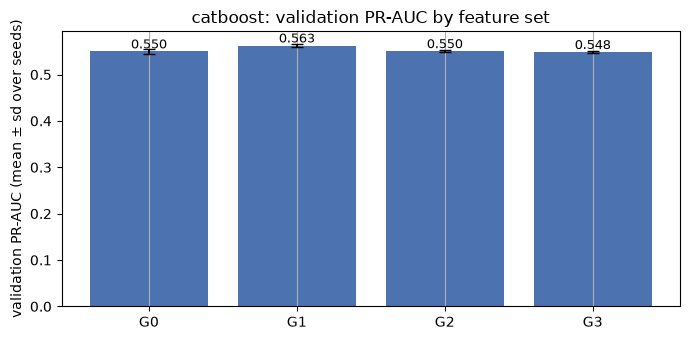

In [9]:
pr = val["pr_auc_mean"]
gains = {f"{a} → {b}": pr[b] - pr[a] for a, b in zip(FEATURE_SETS[:-1], FEATURE_SETS[1:])}
if len(FEATURE_SETS) > 2:
    gains[f"{FEATURE_SETS[0]} → {FEATURE_SETS[-1]}"] = pr[FEATURE_SETS[-1]] - pr[FEATURE_SETS[0]]
display(pd.DataFrame([gains], index=["change in PR-AUC"]).round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(val.index, val["pr_auc_mean"], yerr=val["pr_auc_std"].fillna(0), color="#4C72B0", capsize=4)
for x, y in zip(val.index, val["pr_auc_mean"]):
    ax.text(x, y, f"{y:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("validation PR-AUC (mean ± sd over seeds)")
ax.set_title(f"{model.NAME}: validation PR-AUC by feature set")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

### 5.4 Known vs unknown customers
A validation row is **known** if its `uid` appears in the training block (`src/segments.py`). PR-AUC is the mean over
the seeds, with a 95% bootstrap interval over rows (`N_BOOT` resamples). `10_model_comparison.ipynb` shows the same
split for all models side by side.

In [10]:
N_BOOT = 200
known = segments.known_uid(df["uid"].iloc[val_idx], set(df["uid"].iloc[train_idx]))
rows = []
for name in FEATURE_SETS:
    paths = [PREDS_DIR / f"{model.NAME}_{name}_val_seed{s}.parquet" for s in SEEDS]
    if not all(p.exists() for p in paths):
        print(f"{name}: validation scores not saved for every seed, skipped")
        continue
    preds = [pd.read_parquet(p) for p in paths]
    if not all((p["TransactionID"].to_numpy() == df["TransactionID"].iloc[val_idx].to_numpy()).all() for p in preds):
        raise ValueError(f"{name}: saved scores don't match the validation rows")
    t = segments.segment_pr_auc(preds[0]["isFraud"].to_numpy(), [p["score"].to_numpy() for p in preds], known,
                                n_boot=N_BOOT)
    rows.append(t.assign(feature_set=name))
if rows:
    seg = pd.concat(rows, ignore_index=True)
    display(seg.groupby("segment")[["rows", "fraud"]].first())
    seg["PR-AUC [95% interval]"] = (seg["pr_auc"].map("{:.4f}".format) + " [" + seg["low"].map("{:.3f}".format)
                                    + ", " + seg["high"].map("{:.3f}".format) + "]")
    display(seg.pivot(index="feature_set", columns="segment", values="PR-AUC [95% interval]").reindex(FEATURE_SETS))

,rows,fraud
segment,,
known,28685,640
unknown,30369,1211


segment,known,unknown
feature_set,,
G0,"0.5726 [0.535, 0.611]","0.5512 [0.526, 0.579]"
G1,"0.6034 [0.565, 0.638]","0.5519 [0.527, 0.582]"
G2,"0.5919 [0.555, 0.625]","0.5404 [0.516, 0.571]"
G3,"0.5912 [0.553, 0.623]","0.5397 [0.514, 0.570]"


### 5.5 How the settings affect performance (RQ4)

Read from the tuning runs already in the log, with no extra training: for each tuned setting and each value it
took, the mean time-CV PR-AUC of the combinations tried with that value (dot), and the best and worst of them
(bar). The star marks the chosen value. This model uses random search (20 combinations), so each value is paired with a different mix of other settings; treat the means as indicative, not as a controlled one-at-a-time sweep. The number of trees (boosting models) or epochs (MLP) is not
a tuned setting: early stopping picks it in every fit.

,setting,value,mean,best,worst,combinations
0,depth,4,0.5235,0.5281,0.5112,5
1,depth,6,0.5388,0.5533,0.5233,7
2,depth,8,0.5455,0.5605,0.5217,8
3,l2_leaf_reg,1.0,0.5303,0.5492,0.5217,5
4,l2_leaf_reg,3.0,0.5443,0.5605,0.5281,7
5,l2_leaf_reg,10.0,0.5364,0.5550,0.5112,8
6,learning_rate,0.03,0.5405,0.5605,0.5112,10
7,learning_rate,0.1,0.5348,0.5524,0.5217,10
8,scale_pos_weight,1.0,0.5412,0.5605,0.5112,10
9,scale_pos_weight,balanced,0.5341,0.5480,0.5217,10


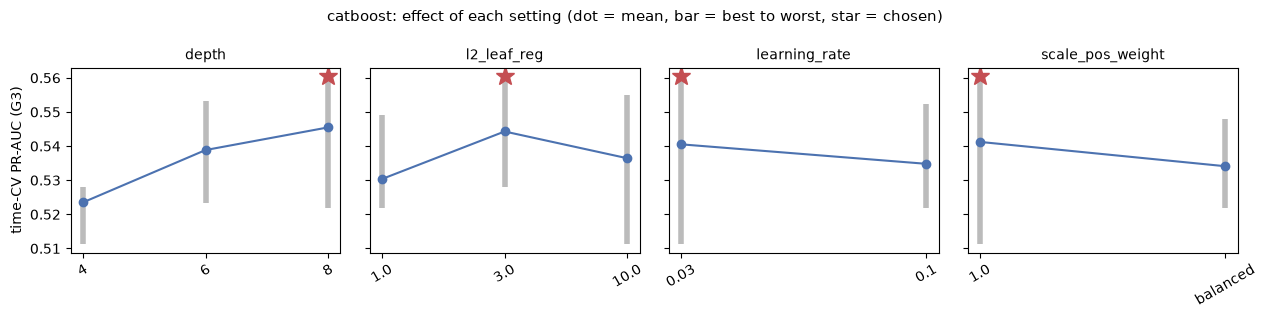

In [11]:
SENS_SET = TUNE_ON or FEATURE_SETS[-1]
sens = experiment.setting_sensitivity(model.NAME, SENS_SET, LOG_PATH)
if sens.empty:
    print("Fewer than two values tried for every setting: nothing to show.")
else:
    display(sens.round(4))
    settings_ = list(dict.fromkeys(sens["setting"]))
    n = len(settings_)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], settings_):
        part = sens[sens["setting"] == name].reset_index(drop=True)
        x = range(len(part))
        ax.vlines(x, part["worst"], part["best"], color="#BBBBBB", lw=4)
        ax.plot(x, part["mean"], "o-", color="#4C72B0")
        picked = chosen[SENS_SET].get(name)
        for i, v in enumerate(part["value"]):
            if v == picked or (picked is None and v == "none"):
                ax.plot(i, part.loc[i, "best"], "*", ms=14, color="#C44E52")
        ax.set_xticks(list(x), [str(v) for v in part["value"]], rotation=30)
        ax.set_title(name, fontsize=10)
    axes[0][0].set_ylabel(f"time-CV PR-AUC ({SENS_SET})")
    fig.suptitle(f"{model.NAME}: effect of each setting (dot = mean, bar = best to worst, star = chosen)", fontsize=11)
    fig.tight_layout()
    plt.show()

## 6. Feature importance

For the chosen settings on `IMPORTANCE_SET` (G3 by default), refit on the training block exactly as in the seed-0
validation run (cached in `results/models/`, so this runs once), then measure:

- **Permutation importance:** how much validation PR-AUC drops when one input column is shuffled (on
  `IMPORTANCE_ROWS` validation rows). It means the same thing for every model, so it can be compared across notebooks.
- **Built-in importance:** CatBoost's prediction values change (how much predictions move with each feature's splits).

Correlated columns share credit: shuffling one leaves its near-copy in place, so a small drop does not prove a column
is useless. Importances describe what this model relies on, not causes of fraud. The table is also saved to
`results/importance/` for `10_model_comparison.ipynb`.

In [12]:
cols = sets[IMPORTANCE_SET]
fitted, pipe = experiment.fit_final(model, lambda: make_pipeline(cols), df, train_idx, chosen[IMPORTANCE_SET],
                                    IMPORTANCE_SET, seed=0, cache_dir=MODELS_DIR)
X_val = pipe.transform(df.iloc[val_idx])
y_val = df["isFraud"].iloc[val_idx].to_numpy()
group_of = importance.feature_groups(spec)

perm = importance.permutation(fitted, X_val, y_val, cols, n_rows=IMPORTANCE_ROWS, seed=0)
built_in = importance.intrinsic(model, fitted, list(X_val.columns), cols)
imp = perm[["pr_auc_drop"]].assign(group=[group_of.get(c, "?") for c in perm.index])
if built_in is not None:
    imp["built_in"] = built_in
    imp["built_in_share"] = built_in / built_in.sum()
imp = imp.sort_values("pr_auc_drop", ascending=False)
print(f"PR-AUC on the {min(IMPORTANCE_ROWS, len(val_idx)):,} rows used: {perm['base_pr_auc'].iloc[0]:.4f} "
      f"(built-in importance: {model.IMPORTANCE or 'none'})")
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
imp.assign(model=model.NAME, feature_set=IMPORTANCE_SET).to_csv(IMPORTANCE_DIR / f"{model.NAME}_{IMPORTANCE_SET}.csv")
display(imp.head(20).round(4))

.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


.venv/lib/python3.13/site-packages/catboost/core.py:2627: UserWarning: Failed to import numba for optimizing custom metrics and objectives
  _check_train_params(params)


PR-AUC on the 20,000 rows used: 0.5347 (built-in importance: prediction values change)


,pr_auc_drop,group,built_in,built_in_share
feature,,,,
C1,0.0923,G0_raw,2.9886,0.0299
C6,0.0427,G0_raw,1.4238,0.0142
C13,0.0400,G0_raw,3.8665,0.0387
C8,0.0307,G0_raw,0.3106,0.0031
C14,0.0261,G0_raw,2.6127,0.0261
C11,0.0215,G0_raw,1.5801,0.0158
C2,0.0164,G0_raw,1.5848,0.0158
C12,0.0151,G0_raw,0.6141,0.0061
fe_D1n,0.0150,G1_row_level,4.6086,0.0461


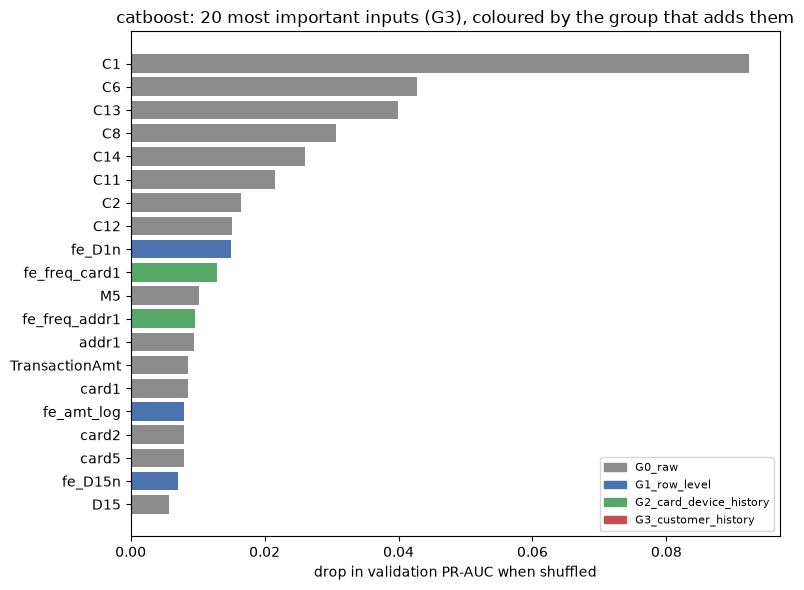

Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):


,sum,count
group,,
G0_raw,0.4715,197
G1_row_level,0.0543,27
G2_card_device_history,0.0289,10
G3_customer_history,0.0096,18


In [13]:
top = imp.head(20).iloc[::-1]
colors = {"G0_raw": "#8C8C8C", "G1_row_level": "#4C72B0", "G2_card_device_history": "#55A868",
          "G3_customer_history": "#C44E52"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pr_auc_drop"], color=[colors.get(g, "#999999") for g in top["group"]])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, list(colors), fontsize=8, loc="lower right")
ax.set_xlabel("drop in validation PR-AUC when shuffled")
ax.set_title(f"{model.NAME}: 20 most important inputs ({IMPORTANCE_SET}), coloured by the group that adds them")
fig.tight_layout()
plt.show()

print("Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):")
display(imp.groupby("group")["pr_auc_drop"].agg(["sum", "count"]).sort_values("sum", ascending=False).round(4))

## 7. Findings

Chosen settings (tuned once on G3, held fixed on every set): depth 8, l2_leaf_reg 3, learning rate 0.03, no class
weighting. Time-CV PR-AUC 0.5605 ± 0.0136 (table 5.1).

- **Feature sets (5.2, 5.3).** Validation PR-AUC is 0.5498 on G0, 0.5625 on G1, 0.5504 on G2 and 0.5485 on G3
  (AUROC 0.9040 to 0.9077). As with XGBoost, the row-level features are the only step that helps: G0 → G1 adds
  0.0128, while G1 → G2 (−0.0122) and G2 → G3 (−0.0019) give it back, so G0 → G3 is −0.0013. Tuning on G3 should
  if anything favour G3, so the card, device and customer history features add nothing for CatBoost.
- **Known vs unknown customers (5.4).** CatBoost scores known customers only slightly higher than unknown ones: 0.5912
  vs 0.5397 on G3, against 0.8414 vs 0.5369 for XGBoost (`07_xgboost.ipynb`, 5.4). On unknown customers the two are
  level; the whole gap between them is on known customers. G0 → G1 lifts known customers by 0.0308 (0.5726 →
  0.6034) and leaves unknown ones unchanged (0.5512 → 0.5519); G2 and G3 lower both slightly, within overlapping
  bootstrap intervals. A likely reason, not tested here: CatBoost grows symmetric trees (every node at a level splits
  on the same feature), which makes it hard to isolate particular combinations of card1, addr1 and fe_D1n, the
  columns that identify a returning customer; and our setup turns off its target statistics (one-hot categories
  only), normally its main strength. So history features do not help known customers here either.
- **Edge of the grid.** Depth 8, the deepest value tried, and learning rate 0.03, the slower one, are both at an edge;
  l2_leaf_reg 3 is in the middle. Deeper trees might help, which would fit the known-customer gap above; this is
  untested.
- **Tree cap.** 2 of the 80 tuning fits and 7 of the 12 validation fits stopped within 50 trees of the 3,000-tree cap
  (three used exactly 3,000), so many validation fits were still improving when they stopped. Every set is affected,
  so the comparison between sets holds, but the scores may be slightly low. The cap is kept at 3,000 so all boosting
  models share it; this is a stated limitation, as for XGBoost.
- **Spread between seeds.** Small on every set (sd 0.0023 to 0.0045 in PR-AUC).
- **Settings that matter (5.5).** Depth matters most: mean CV PR-AUC rises from 0.5235 at depth 4 to 0.5455 at depth
  8. l2_leaf_reg 3 does best on average (0.5443, against 0.5303 at 1 and 0.5364 at 10). The learning rate (0.5405 vs
  0.5348) and class weighting (0.5412 unweighted vs 0.5341 balanced) move the mean less; the five best settings are
  all unweighted.
- **Inputs that matter (6).** The raw C columns dominate: C1 is by far the most important input (PR-AUC drop
  0.0923), followed by C6 (0.0427), C13 (0.0400) and C8 (0.0307), and eight of the top ten are raw columns. The
  engineered features that rank highest are fe_D1n (9th, 0.0150), fe_freq_card1 (10th, 0.0129) and fe_freq_addr1
  (12th). By group, the summed drop is 0.4715 for G0 (197 columns), 0.0543 for G1 (27), 0.0289 for G2 (10) and
  0.0096 for G3 (18); the best customer-history feature, fe_uid_c13_rel_prior_mean, is 31st (drop 0.0047). Compared
  with XGBoost, CatBoost leans more on the C counts and less on card1, addr1 and TransactionAmt, which fits it doing
  less to pick out individual customers.
- **Warnings in the outputs.** The repeated "Failed to import numba for optimizing custom metrics" warnings in
  section 4 are harmless: numba would only speed up the Python PR-AUC metric used for early stopping, not change it.